## A.1: Shoot the pictures

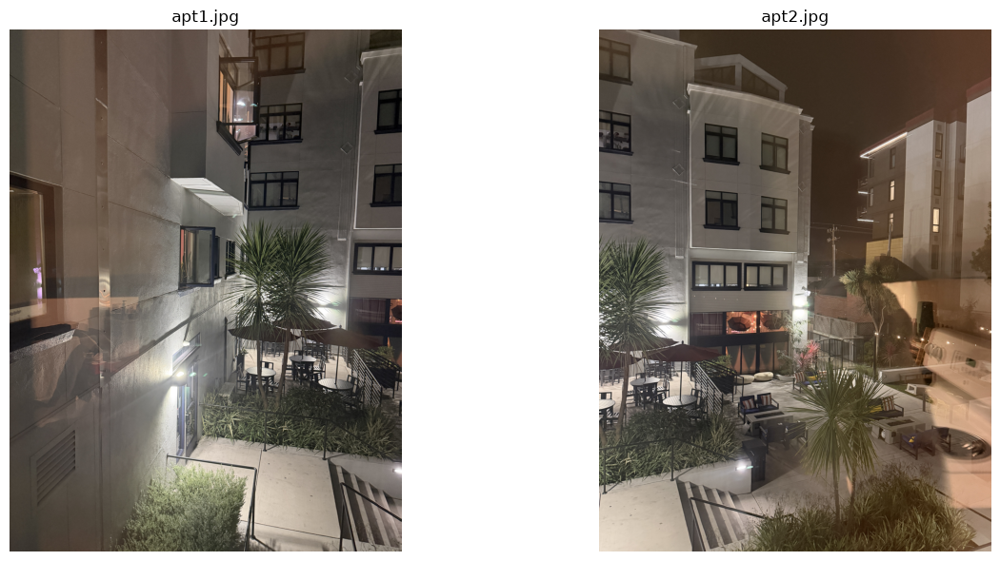

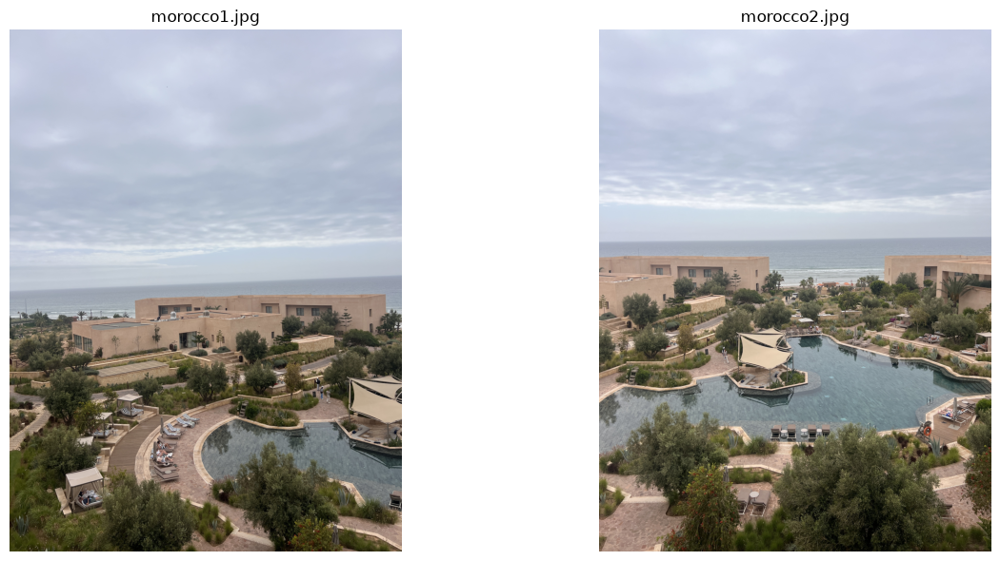

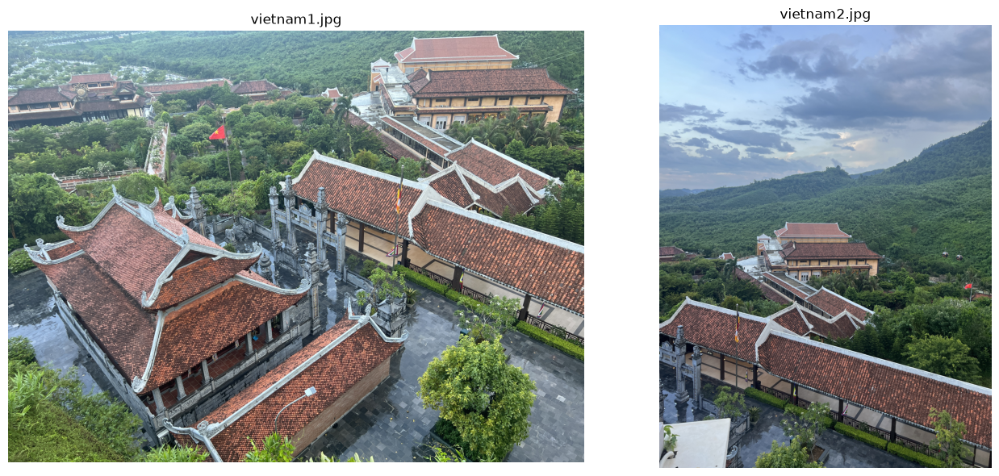

In [1]:
import skimage as sk
from PIL import Image, ImageOps
import skimage.io as skio
import matplotlib.pyplot as plt

def img_to_rgb(imname):
    with Image.open(imname) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize(
            (max(1, im.width // 2), max(1, im.height // 2)),
            Image.Resampling.LANCZOS,
        )
    im = sk.img_as_float(im)

    return im

images = []
imfiles = ['apt1.jpg', 'apt2.jpg', 'morocco1.jpg', 'morocco2.jpg', 'vietnam1.jpg', 'vietnam2.jpg']

for imname in imfiles:
    images.append(img_to_rgb('../images/' + imname))

for i in range(0, len(images), 2):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, im, imname in zip(axes, images[i:i + 2], imfiles[i:i + 2]):
        ax.imshow(im)
        ax.set_title(imname)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [2]:
[im.shape for im in images]

[(2856, 2142, 3),
 (2856, 2142, 3),
 (2016, 1512, 3),
 (2016, 1512, 3),
 (1512, 2016, 3),
 (2016, 1512, 3)]

## A.2: Recover homographies

In [3]:
apt_points = {"im1_name":"apt1","im2_name":"apt2","im1Points":[[3138,1947],[3699,1287],[3622,3259],[4103,3204],[3474,4270],[3858,260],[4061,784]],"im2Points":[[338,2095],[878,1543],[922,3443],[1358,3322],[801,4488],[995,591],[1178,1126]]}


In [4]:
morocco_points = {"im1_name":"morocco1","im2_name":"morocco2","im1Points":[[2616,2701],[2636,2909],[1789,2978],[2629,3530],[1640,3571],[1719,3890],[2800,2310],[1999,2163]],"im2Points":[[1068,2351],[1099,2571],[247,2727],[1084,3093],[88,3349],[184,3660],[1237,2003],[464,1872]]}

In [29]:
vietnam_points = vietnam_points = {"im1_name":"vietnam1","im2_name":"vietnam2","im1Points":[[2836,55],[3572,184],[2837,455],[2244,411],[2162,888],[2946,1192],[2222,1293],[3125,1829]],"im2Points":[[1161,1795],[1748,1923],[1133,2119],[590,2080],[260,2508],[1010,2788],[207,2953],[1227,3456]]}



In [30]:
import numpy as np

def computeH(im1_pts, im2_pts):
    A, b = [], []

    for pts1, pts2 in zip(im1_pts, im2_pts):
        x1, y1 = pts1[0], pts1[1]
        x2, y2 = pts2[0], pts2[1]

        A.append([x1, y1, 1, 0, 0, 0, -x1 * x2, -y1 * x2])
        A.append([0, 0, 0, x1, y1, 1, -x1 * y2, -y1*y2])
        b.extend([x2, y2])

    h = np.linalg.lstsq(A, b, rcond=None)[0]
    err = np.sum((A @ h - b) ** 2)
    return np.append(h, 1).reshape(3, 3), err

In [31]:
# Points were clicked on the full-res images; img_to_rgb halves them.
apt1_pts = np.asarray(apt_points['im1Points'], dtype=float) / 2
apt2_pts = np.asarray(apt_points['im2Points'], dtype=float) / 2
mor1_pts = np.asarray(morocco_points['im1Points'], dtype=float) / 2
mor2_pts = np.asarray(morocco_points['im2Points'], dtype=float) / 2
vie1_pts = np.asarray(vietnam_points['im1Points'], dtype=float) / 2
vie2_pts = np.asarray(vietnam_points['im2Points'], dtype=float) / 2

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch

def show_correspondences(im1, im2, pts1, pts2, title1, title2):
    pts1 = np.asarray(pts1) 
    pts2 = np.asarray(pts2) 

    if pts1.shape != pts2.shape:
        raise ValueError("Both point arrays must have the same shape.")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    ax1.imshow(im1)
    ax2.imshow(im2)

    colors = plt.cm.hsv(np.linspace(0, 1, len(pts1), endpoint=False))

    for p1, p2, color in zip(pts1, pts2, colors):
        ax1.scatter(*p1, color=color, s=70, edgecolors="black", zorder=3)
        ax2.scatter(*p2, color=color, s=70, edgecolors="black", zorder=3)

        line = ConnectionPatch(
            xyA=p1, xyB=p2,
            coordsA="data", coordsB="data",
            axesA=ax1, axesB=ax2,
            color=color, linewidth=1.5, alpha=0.8
        )
        fig.add_artist(line)

    ax1.set_title(title1)
    ax2.set_title(title2)
    ax1.axis("off")
    ax2.axis("off")
    plt.tight_layout()
    plt.show()


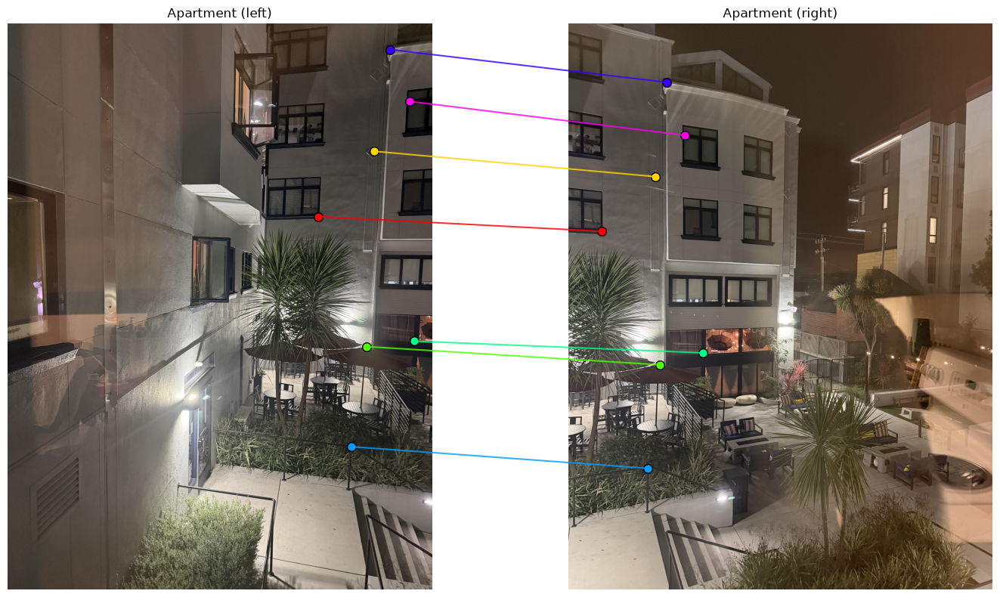

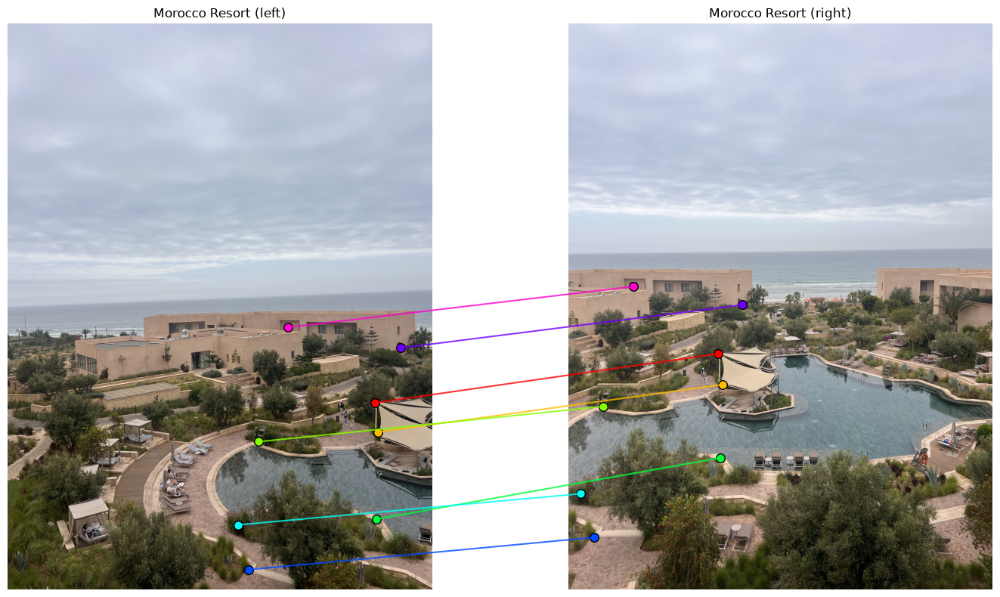

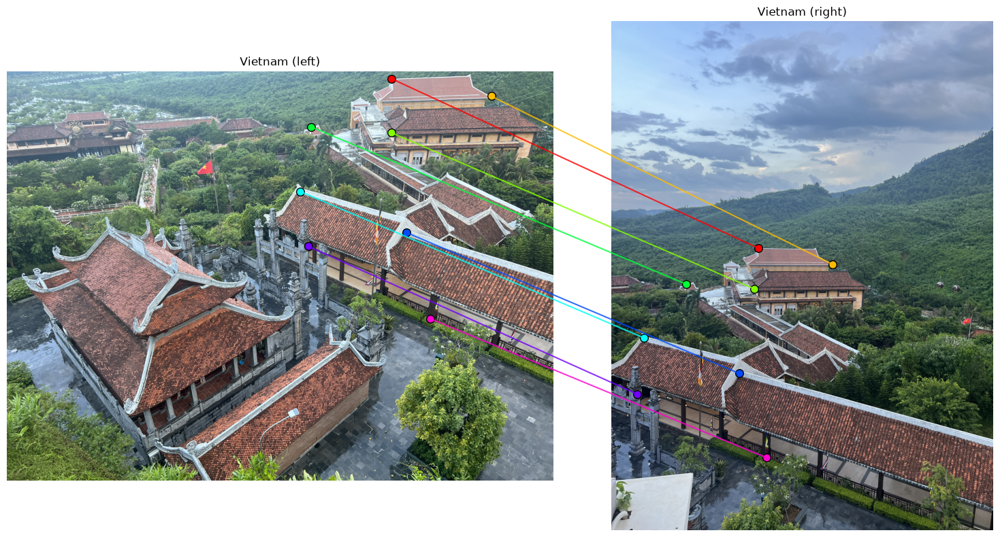

In [33]:
show_correspondences(images[0], images[1], apt1_pts, apt2_pts, "Apartment (left)", "Apartment (right)")
show_correspondences(images[2], images[3], mor1_pts, mor2_pts, "Morocco Resort (left)", "Morocco Resort (right)")
show_correspondences(images[4], images[5], vie1_pts, vie2_pts, "Vietnam (left)", "Vietnam (right)")

In [34]:
h1, err1 = computeH(apt1_pts, apt2_pts)
h2, err2 = computeH(mor1_pts, mor2_pts)
h3, err3 = computeH(vie1_pts, vie2_pts)

np.set_printoptions(precision=4, suppress=True)
for name, H, err in [("Apartment", h1, err1), ("Morocco", h2, err2), ("Vietnam", h3, err3)]:
    print(f"{name} H =\n{H}\nleast-squares residual = {err:.3g}\n")

Apartment H =
[[    1.7272     0.0608 -2510.1301]
 [    0.4873     1.5034  -623.0201]
 [    0.0004    -0.         1.    ]]
least-squares residual = 1.48e+03

Morocco H =
[[    1.7565     0.0329 -1434.942 ]
 [    0.4187     1.6006  -713.7074]
 [    0.0005     0.0001     1.    ]]
least-squares residual = 699

Vietnam H =
[[   1.0456   -0.4116 -805.3434]
 [   0.0875    0.3373  917.6344]
 [   0.0001   -0.0004    1.    ]]
least-squares residual = 4.41e+03



In [35]:
from IPython.display import display, Math


def build_system(im1_pts, im2_pts):
    # Same rows computeH builds: two equations per correspondence, A h = b.
    A, b = [], []
    for (x1, y1), (x2, y2) in zip(im1_pts, im2_pts):
        A.append([x1, y1, 1, 0, 0, 0, -x1 * x2, -y1 * x2])
        A.append([0, 0, 0, x1, y1, 1, -x1 * y2, -y1 * y2])
        b.extend([x2, y2])
    return np.array(A, dtype=float), np.array(b, dtype=float)


def matrix_latex(M, fmt="{:.4g}"):
    M = np.atleast_2d(M)
    rows = [" & ".join(fmt.format(v if abs(v) > 1e-9 else 0) for v in row) for row in M]
    return r"\begin{bmatrix}" + r" \\ ".join(rows) + r"\end{bmatrix}"


def show_system(name, im1_pts, im2_pts, n_show=2):
    im1_pts, im2_pts = np.asarray(im1_pts, float), np.asarray(im2_pts, float)
    A, b = build_system(im1_pts, im2_pts)
    H, err = computeH(im1_pts, im2_pts)
    proj = (H @ np.column_stack([im1_pts, np.ones(len(im1_pts))]).T)
    proj = (proj[:2] / proj[2]).T
    reproj = np.linalg.norm(proj - im2_pts, axis=1)

    print(f"===== {name}: {len(im1_pts)} correspondences -> A is {A.shape}, b is {b.shape}")
    display(Math(
        r"\begin{bmatrix} x & y & 1 & 0 & 0 & 0 & -xx' & -yx' \\ "
        r"0 & 0 & 0 & x & y & 1 & -xy' & -yy' \end{bmatrix}"
        r"\begin{bmatrix} a \\ b \\ c \\ d \\ e \\ f \\ g \\ h \end{bmatrix}"
        r"= \begin{bmatrix} x' \\ y' \end{bmatrix}"
    ))
    print(f"First {n_show} correspondences ({2 * n_show} of {len(A)} rows):")
    display(Math(matrix_latex(A[:2 * n_show]) + r"\,\mathbf{h} = " + matrix_latex(b[:2 * n_show, None])))
    display(Math(r"H = " + matrix_latex(H)))
    print(f"Least-squares residual: {err:.3g}   "
          f"reprojection error: mean {reproj.mean():.2f} px, max {reproj.max():.2f} px\n")


show_system("Apartment", apt1_pts, apt2_pts)
show_system("Morocco Resort", mor1_pts, mor2_pts)
show_system("Vietnam", vie1_pts, vie2_pts)

===== Apartment: 7 correspondences -> A is (14, 8), b is (14,)


<IPython.core.display.Math object>

First 2 correspondences (4 of 14 rows):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

First 2 correspondences (4 of 16 rows):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Least-squares residual: 4.41e+03   reprojection error: mean 23.53 px, max 41.05 px



## A.3: Warp the images

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def warp_coordinates(im, H):
    h, w = im.shape[:2]

    corners = np.array([
        [0, 0, 1], [w-1, 0, 1],
        [0, h-1, 1], [w-1, h-1, 1]
    ]).T

    corners = H @ corners
    corners = corners[:2] / corners[2]

    xmin, ymin = np.floor(corners.min(axis=1)).astype(int)
    xmax, ymax = np.ceil(corners.max(axis=1)).astype(int)

    X, Y = np.meshgrid(
        np.arange(xmin, xmax + 1),
        np.arange(ymin, ymax + 1)
    )

    p = np.linalg.inv(H) @ np.array([
        X.ravel(), Y.ravel(), np.ones(X.size)
    ])

    x = np.full(X.size, -1.0)
    y = np.full(X.size, -1.0)
    finite = np.abs(p[2]) > 1e-12
    x[finite] = p[0, finite] / p[2, finite]
    y[finite] = p[1, finite] / p[2, finite]

    valid = finite & (x >= 0) & (x <= w-1) & (y >= 0) & (y <= h-1)

    return x, y, valid, X.shape

In [37]:
# from skimage.util import img_as_float

def warpNN(im, H):
    x, y, valid, shape = warp_coordinates(im, H)

    xi = np.floor(x[valid] + 0.5).astype(int)
    yi = np.floor(y[valid] + 0.5).astype(int)

    out = np.zeros((len(x),) + im.shape[2:])
    out[valid] = im[yi, xi]

    return out.reshape(shape + im.shape[2:]), valid.reshape(shape)

def warpBilinear(im, H):
    x, y, valid, shape = warp_coordinates(im, H)
    h, w = im.shape[:2]

    x, y = x[valid], y[valid]
    x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
    x1, y1 = np.minimum(x0 + 1, w-1), np.minimum(y0 + 1, h-1)

    dx, dy = x - x0, y - y0

    if im.ndim == 3:
        dx, dy = dx[:, None], dy[:, None]

    out = np.zeros((valid.size,) + im.shape[2:], dtype=float)
    out[valid] = (
        (1-dx) * (1-dy) * im[y0, x0]
        + dx * (1-dy) * im[y0, x1]
        + (1-dx) * dy * im[y1, x0]
        + dx * dy * im[y1, x1]
    )

    return out.reshape(shape + im.shape[2:]), valid.reshape(shape)

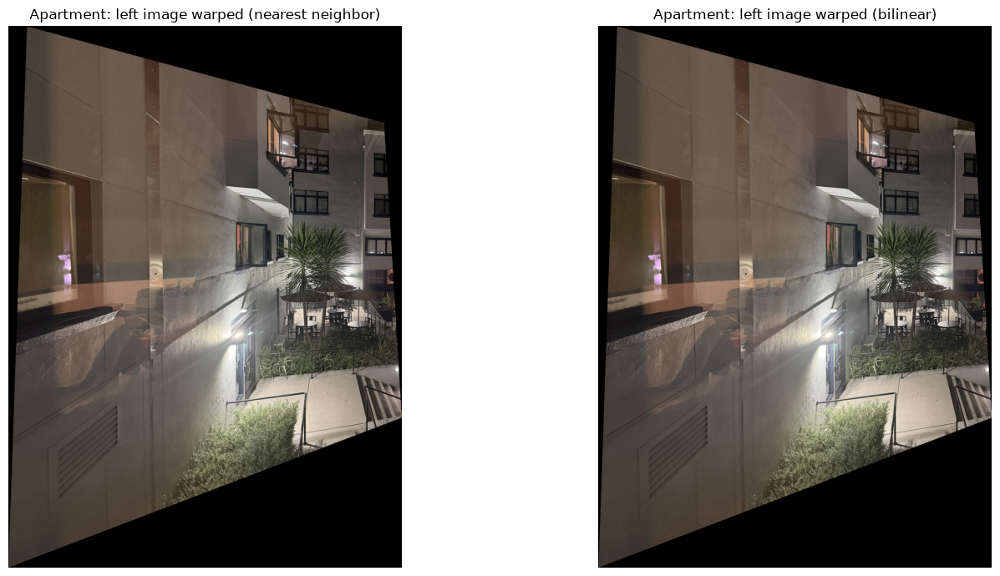

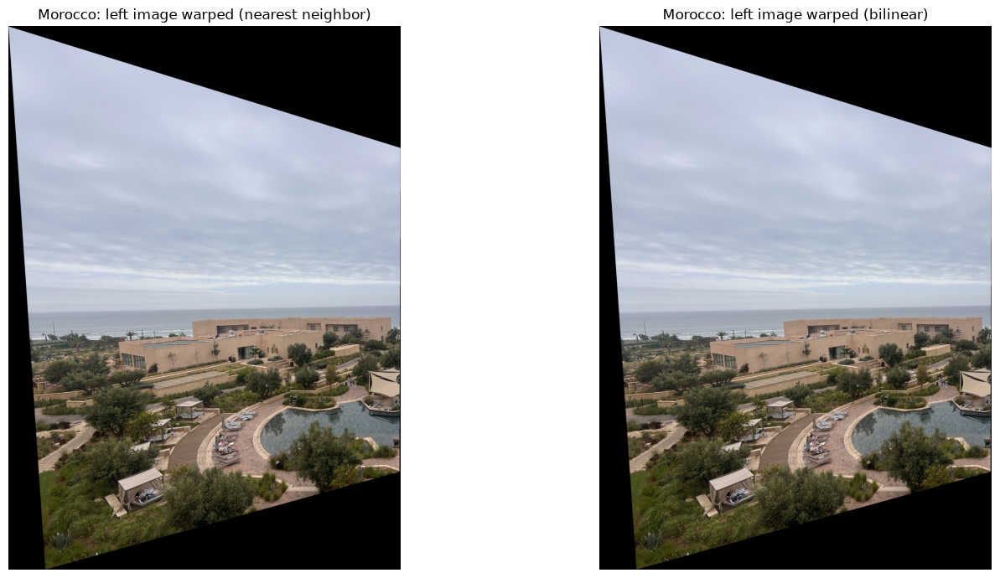

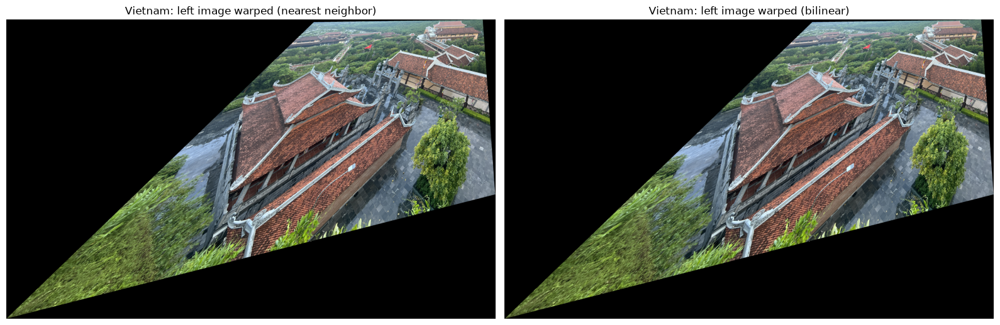

In [38]:
for name, im, H in [("Apartment", images[0], h1), ("Morocco", images[2], h2), ("Vietnam", images[4], h3)]:
    im_nn, _ = warpNN(im, H)
    im_b, _ = warpBilinear(im, H)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(np.clip(im_nn, 0, 1))
    axes[0].set_title(f"{name}: left image warped (nearest neighbor)")
    axes[1].imshow(np.clip(im_b, 0, 1))
    axes[1].set_title(f"{name}: left image warped (bilinear)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Rectification

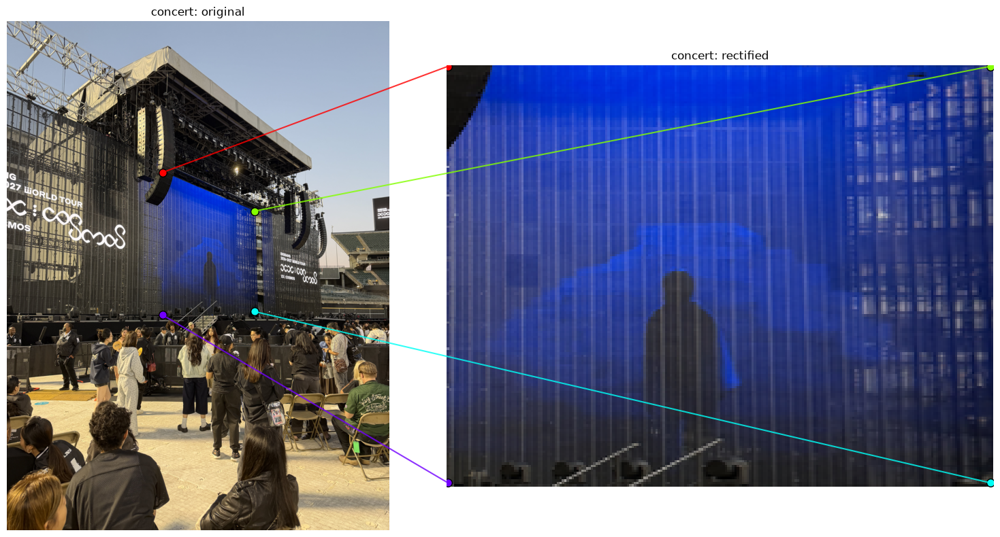

concert H =
[[   0.4912   -0.     -179.7909]
 [  -0.1451    0.346   -70.0671]
 [  -0.0009    0.        1.    ]]



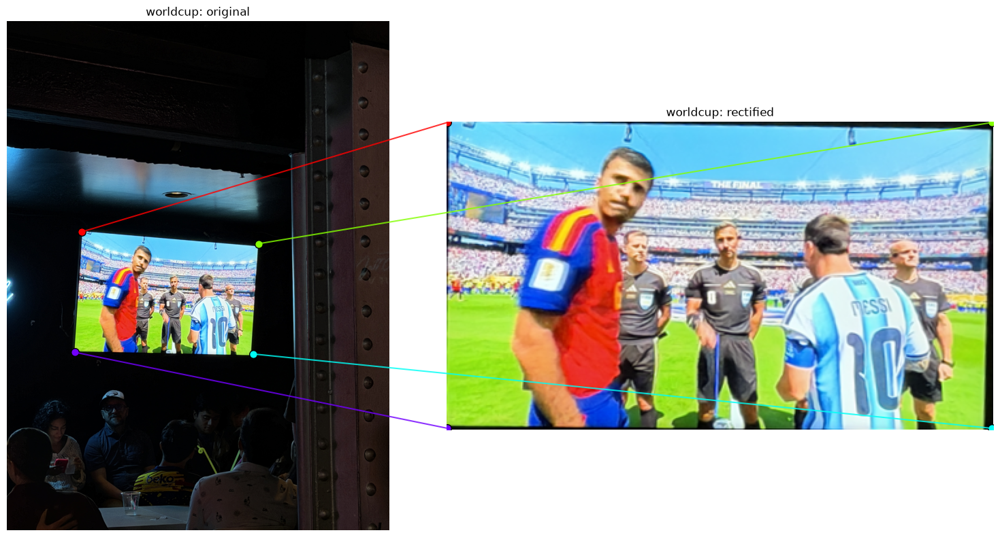

worldcup H =
[[   0.8911    0.0502 -181.7254]
 [  -0.0544    0.8076 -390.9967]
 [  -0.0002    0.        1.    ]]



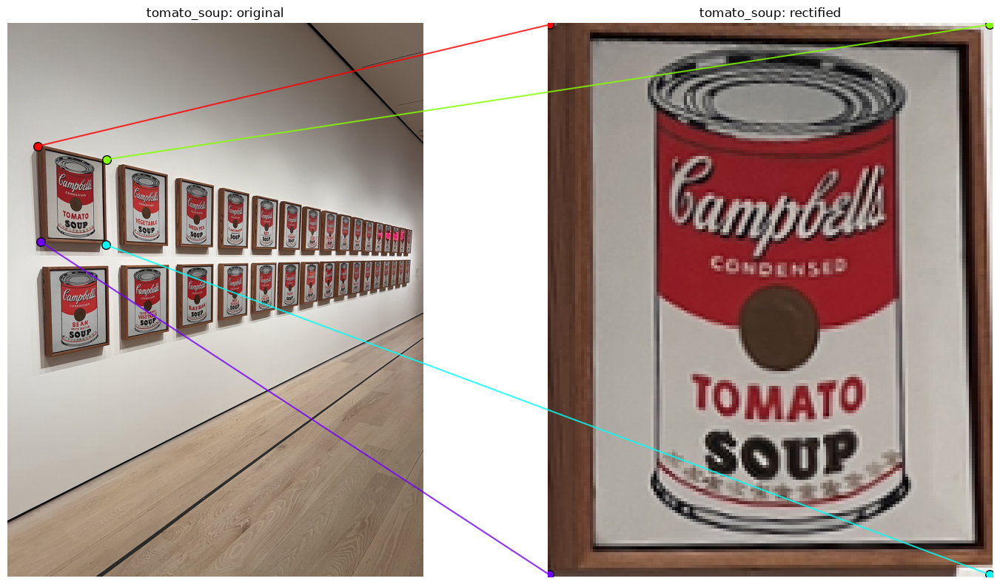

tomato_soup H =
[[   0.7925   -0.0229  -46.2244]
 [  -0.1464    0.7472 -189.0813]
 [  -0.0006   -0.0002    1.    ]]



In [39]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import skimage as sk

MAX_DIM = 1200   # longest side after resizing
MARGIN = 0.0    # crop margin around the rectangle, as a fraction of its size


def img_to_rgb_1200(imname):
    with Image.open(imname) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        scale = MAX_DIM / max(im.size)
        im = im.resize(
            (round(im.width * scale), round(im.height * scale)),
            Image.Resampling.LANCZOS,
        )
    return sk.img_as_float(im)


def target_rectangle(pts, aspect):
    pts = np.asarray(pts, dtype=float)
    w = (np.linalg.norm(pts[1] - pts[0]) + np.linalg.norm(pts[2] - pts[3])) / 2
    h = w / aspect
    return np.array([[0, 0], [w, 0], [w, h], [0, h]])


def warp_offset(im, H):
    h, w = im.shape[:2]
    corners = H @ np.array([[0, 0, 1], [w-1, 0, 1], [0, h-1, 1], [w-1, h-1, 1]]).T
    corners = corners[:2] / corners[2]
    return np.floor(corners.min(axis=1))


rectifications = {
    "concert":     ([[366, 356], [583, 447], [583, 684], [366, 692]], 1.3),  
    "worldcup":    ([[176, 496], [592, 524], [580, 784], [160, 780]], 16/9),  
    "tomato_soup": ([[66, 266], [214, 295], [212, 480], [72, 474]], 0.8),    
}

for name, (pts, aspect) in rectifications.items():
    im = img_to_rgb_1200(f"../images/{name}.jpg")
    rect = target_rectangle(pts, aspect)
    H, err = computeH(pts, rect)
    rec, mask = warpBilinear(im, H)
    rect_out = rect - warp_offset(im, H)    

    (x0, y0), (x1, y1) = rect_out.min(axis=0), rect_out.max(axis=0)
    mx, my = MARGIN * (x1 - x0), MARGIN * (y1 - y0)
    cx0, cy0 = int(max(0, x0 - mx)), int(max(0, y0 - my))
    cx1, cy1 = int(min(rec.shape[1], np.ceil(x1 + mx) + 1)), int(min(rec.shape[0], np.ceil(y1 + my) + 1))
    rec_crop = np.clip(rec[cy0:cy1, cx0:cx1], 0, 1)

    show_correspondences(im, rec_crop, pts, rect_out - [cx0, cy0],
                         f"{name}: original", f"{name}: rectified")
    print(f"{name} H =\n{np.round(H, 4)}\n")

In [40]:
for name, (pts, aspect) in rectifications.items():
    show_system(f"{name} (rectification)", pts, target_rectangle(pts, aspect))

===== concert (rectification): 4 correspondences -> A is (8, 8), b is (8,)


<IPython.core.display.Math object>

First 2 correspondences (4 of 8 rows):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

First 2 correspondences (4 of 8 rows):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Least-squares residual: 1.73e-19   reprojection error: mean 0.00 px, max 0.00 px



### Nearest neighbor vs. bilinear

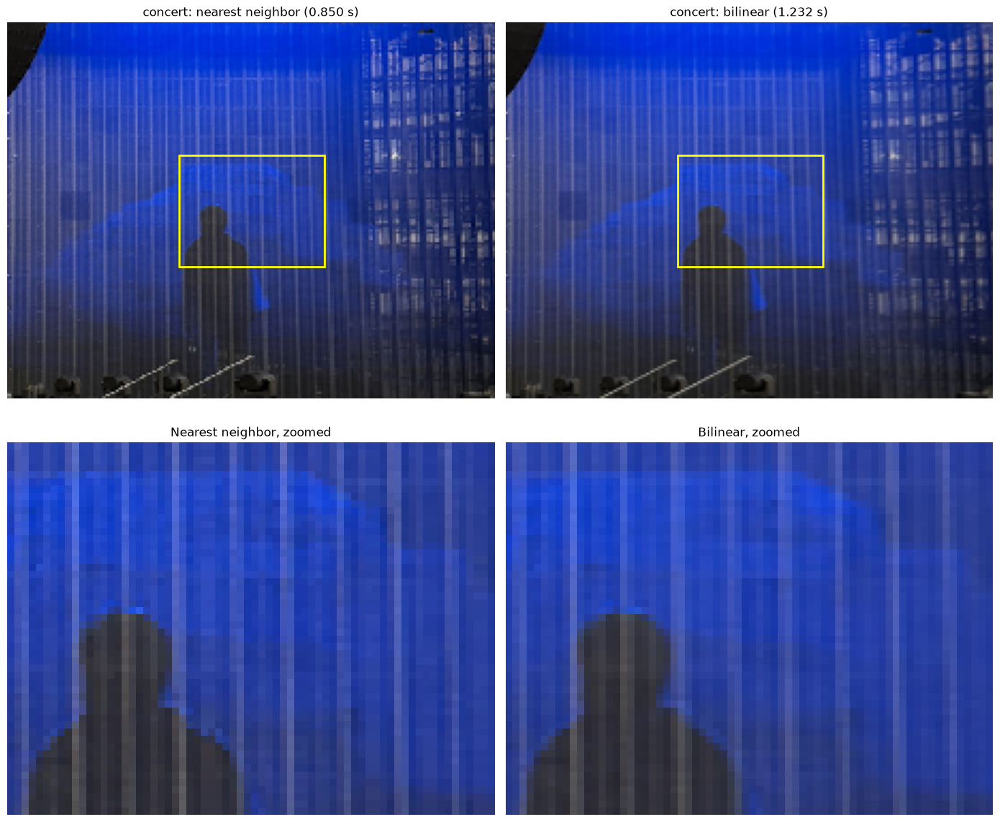

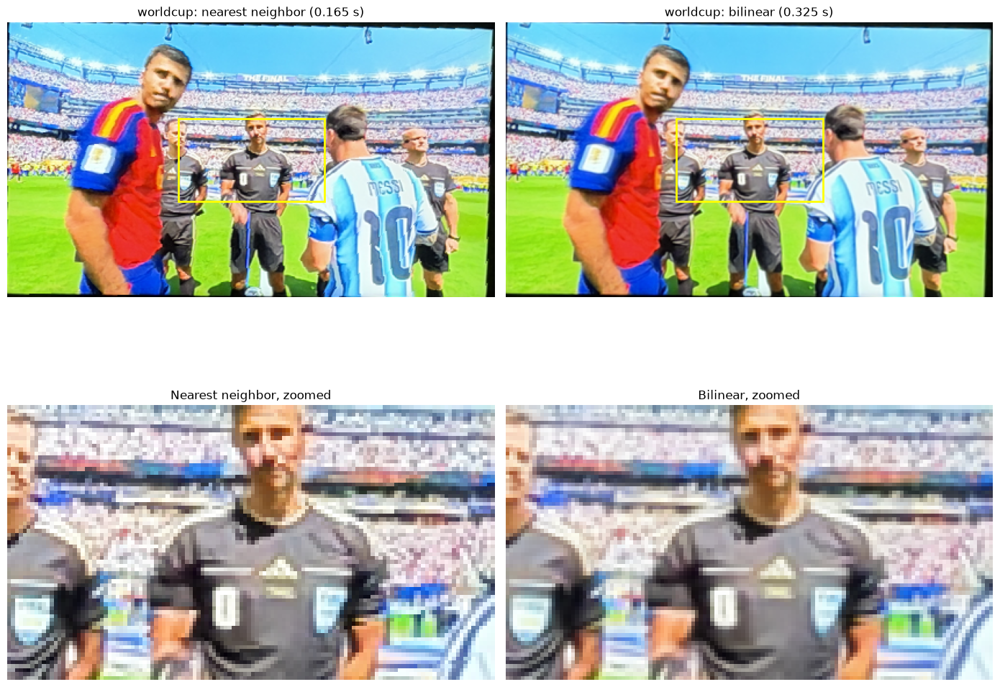

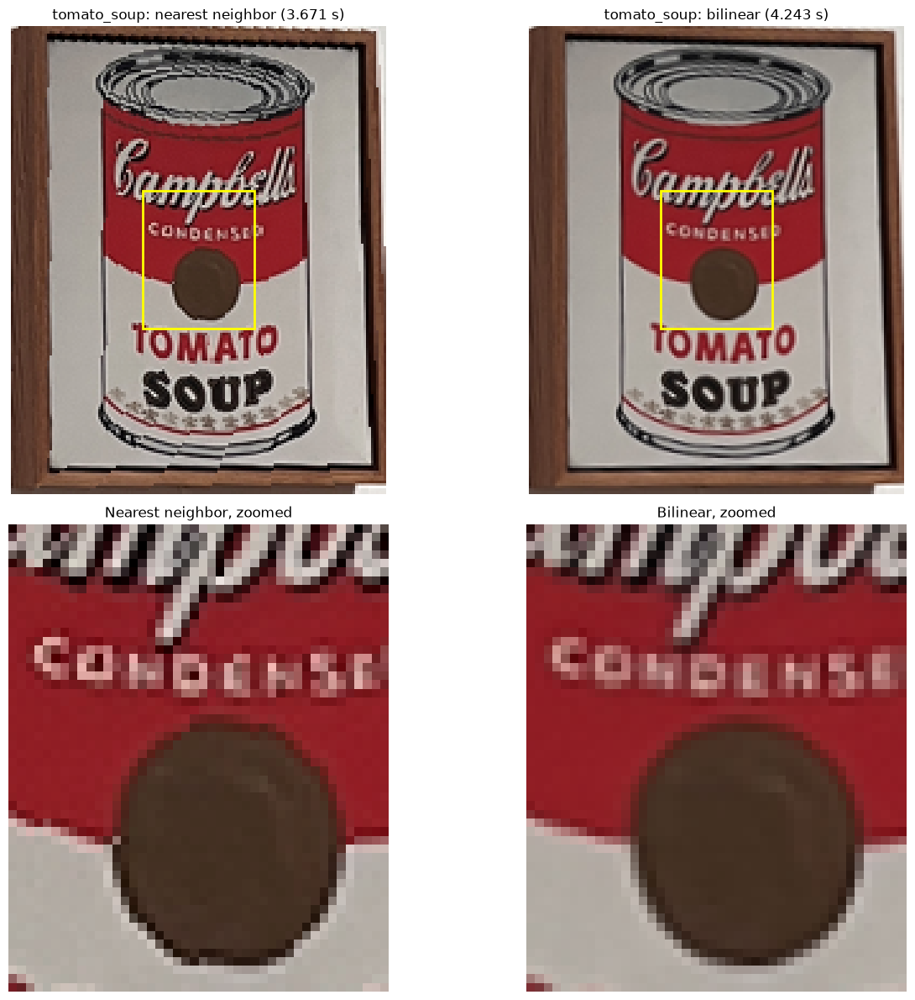

image              output size    NN (s)  bilinear (s)   ratio
concert            2250 x 1600     0.850         1.232     1.4x
worldcup            1169 x 996     0.165         0.325     2.0x
tomato_soup        3993 x 3732     3.671         4.243     1.2x


In [41]:
import time

ZOOM = 0.3   # zoom crop size, as a fraction of the rectangle


def crop_to_rect(rec, rect_out):
    (x0, y0), (x1, y1) = rect_out.min(axis=0), rect_out.max(axis=0)
    cx0, cy0 = int(max(0, x0)), int(max(0, y0))
    cx1, cy1 = int(min(rec.shape[1], np.ceil(x1) + 1)), int(min(rec.shape[0], np.ceil(y1) + 1))
    return np.clip(rec[cy0:cy1, cx0:cx1], 0, 1)


timings = {}
for name, (pts, aspect) in rectifications.items():
    im = img_to_rgb_1200(f"../images/{name}.jpg")
    rect = target_rectangle(pts, aspect)
    H, _ = computeH(pts, rect)
    rect_out = rect - warp_offset(im, H)

    t = time.perf_counter()
    rec_nn, _ = warpNN(im, H)
    t_nn = time.perf_counter() - t
    t = time.perf_counter()
    rec_bil, _ = warpBilinear(im, H)
    t_bil = time.perf_counter() - t
    timings[name] = (rec_nn.shape[:2], t_nn, t_bil)

    nn, bil = crop_to_rect(rec_nn, rect_out), crop_to_rect(rec_bil, rect_out)
    h, w = nn.shape[:2]
    zh, zw = int(h * ZOOM), int(w * ZOOM)
    zy, zx = (h - zh) // 2, (w - zw) // 2

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes[0, 0].imshow(nn)
    axes[0, 0].set_title(f"{name}: nearest neighbor ({t_nn:.3f} s)")
    axes[0, 1].imshow(bil)
    axes[0, 1].set_title(f"{name}: bilinear ({t_bil:.3f} s)")
    for ax in axes[0]:
        ax.add_patch(plt.Rectangle((zx, zy), zw, zh, fill=False, edgecolor="yellow", lw=2))
    axes[1, 0].imshow(nn[zy:zy + zh, zx:zx + zw], interpolation="nearest")
    axes[1, 0].set_title("Nearest neighbor, zoomed")
    axes[1, 1].imshow(bil[zy:zy + zh, zx:zx + zw], interpolation="nearest")
    axes[1, 1].set_title("Bilinear, zoomed")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"{'image':<14}{'output size':>16}{'NN (s)':>10}{'bilinear (s)':>14}{'ratio':>8}")
for name, ((oh, ow), t_nn, t_bil) in timings.items():
    print(f"{name:<14}{f'{oh} x {ow}':>16}{t_nn:>10.3f}{t_bil:>14.3f}{t_bil / t_nn:>8.1f}x")

## A.4: Blend the images into a mosaic

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import img_as_float

def feather_weights(im):
    h, w = im.shape[:2]
    y, x = np.indices((h, w))

    weights = np.minimum.reduce([
        x + 1, w - x,
        y + 1, h - y
    ]).astype(float)

    return weights / weights.max()


def make_mosaic(im1, im2, H):
    im1 = img_as_float(im1)
    im2 = img_as_float(im2)

    h1, w1 = im1.shape[:2]
    h2, w2 = im2.shape[:2]

    corners = H @ np.array([[0, 0, 1], [w1-1, 0, 1], [0, h1-1, 1], [w1-1, h1-1, 1]]).T
    corners = corners[:2] / corners[2]
    xmin = max(min(0, np.floor(corners[0].min())), -(w2 // 2))
    ymin = max(min(0, np.floor(corners[1].min())), -(h2 // 2))
    xmax = min(max(w2 - 1, np.ceil(corners[0].max())), w2 - 1 + w2 // 2)
    ymax = min(max(h2 - 1, np.ceil(corners[1].max())), h2 - 1 + h2 // 2)

    shape = (int(ymax - ymin) + 1, int(xmax - xmin) + 1)

    T = np.array([
        [1, 0, -xmin],
        [0, 1, -ymin],
        [0, 0, 1]
    ], dtype=float)

    X, Y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    canvas_points = np.array([
        X.ravel(), Y.ravel(), np.ones(X.size)
    ])

    total = np.zeros(shape + (3,))
    total_weights = np.zeros(shape)

    for im, M in [(im1, T @ H), (im2, T)]:
        h, w = im.shape[:2]

        p = np.linalg.inv(M) @ canvas_points
        x = np.full(X.size, -1.0)
        y = np.full(X.size, -1.0)

        finite = np.abs(p[2]) > 1e-12
        x[finite] = p[0, finite] / p[2, finite]
        y[finite] = p[1, finite] / p[2, finite]

        valid = finite & (x >= 0) & (x <= w-1) & (y >= 0) & (y <= h-1)

        x, y = x[valid], y[valid]
        x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
        x1, y1 = np.minimum(x0 + 1, w-1), np.minimum(y0 + 1, h-1)
        dx, dy = x - x0, y - y0

        source = np.dstack([im, feather_weights(im)])
        values = (
            ((1-dx) * (1-dy))[:, None] * source[y0, x0]
            + (dx * (1-dy))[:, None] * source[y0, x1]
            + ((1-dx) * dy)[:, None] * source[y1, x0]
            + (dx * dy)[:, None] * source[y1, x1]
        )

        weights = values[:, 3]
        total.reshape(-1, 3)[valid] += values[:, :3] * weights[:, None]
        total_weights.ravel()[valid] += weights

    mosaic = total / np.maximum(total_weights[..., None], 1e-12)
    return mosaic, total_weights > 0

In [43]:
def show_mosaic(im1, im2, H):
    mosaic, mask = make_mosaic(im1, im2, H)

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    axes[0].imshow(im1)
    axes[0].set_title("Source 1")

    axes[1].imshow(im2)
    axes[1].set_title("Source 2")

    axes[2].imshow(mosaic, alpha=mask.astype(float))
    axes[2].set_title("Feathered mosaic")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return mosaic

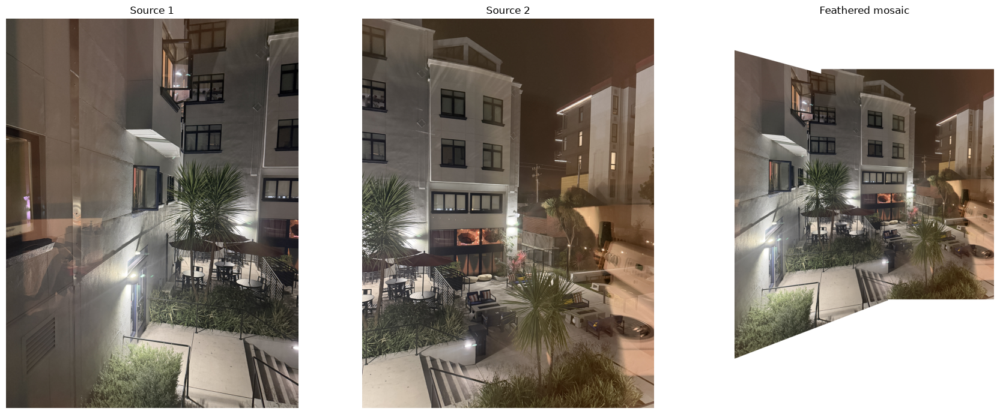

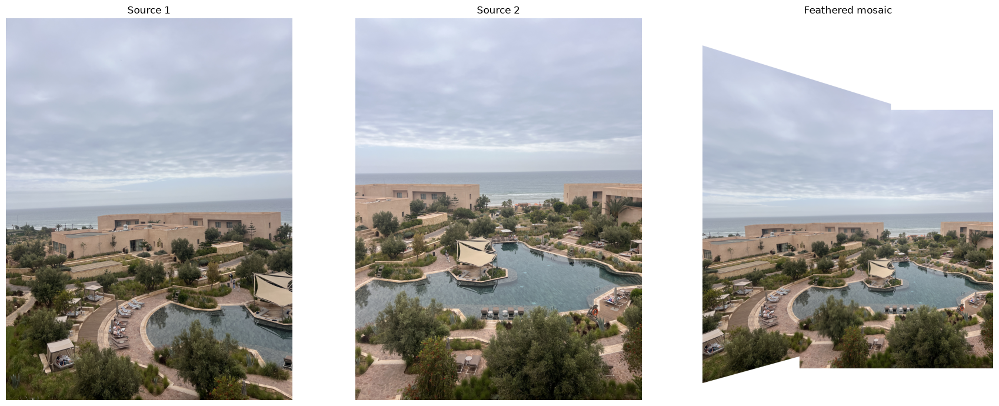

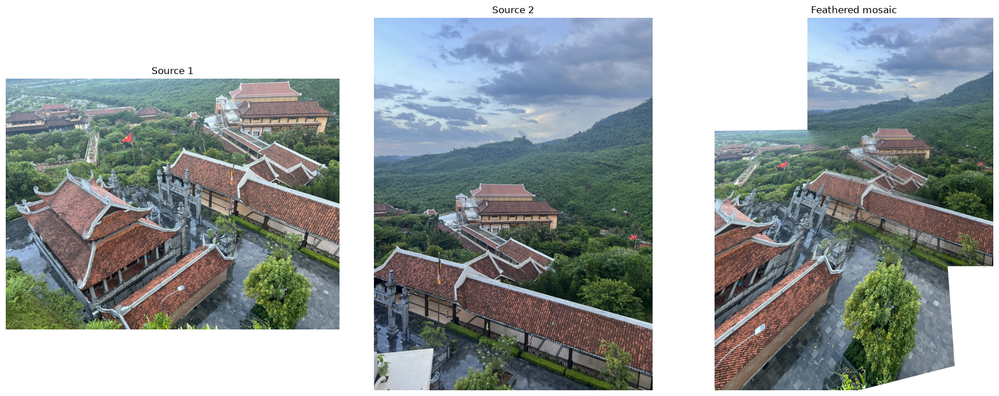

In [44]:
# Points are already scaled to the half-size images (see the points cell).
mosaic1 = show_mosaic(images[0], images[1], h1)
mosaic2 = show_mosaic(images[2], images[3], h2)
mosaic3 = show_mosaic(images[4], images[5], h3)